# M4L1 - Data Carpentry with `R`

In this course, we use `R` for the analysis of our results within our RNA-Seq pipelines. Mainly, `R` is used to analyze counts from mapped reads. In this Module, you will gain some basic experience using `R` for the analysis of count data. We will start slowly and quickly move forward to the use of statistics, so it is recommended to use AI to help you understand code. The goal of this week is not to learn how to program, but to understand the concepts behind the statistical analysis used in RNA-Seq pipelines. 

**NOTE:** We are going to be using `R` within this notebook within our `Module 3 - R` Kernel. If you have not completed this or had issues in M3P2, you can use the global environment `the course-wide Module 3 environment (see `environment/module_3_rnaseq_salmon.yml`)` and install `irkernel` to your Jupyter Session manually. 

This Notebook will focus on the fundamentals of `R`, including how logical operators, variable assignment, and data storage within the `R` programming language function in the context of our biological data sets. 

### What we will cover...
- Variables
- Operators
- Data frames
- Functions
- Packages



### ***R Programming within Jupyter Notebook***
Below is a code cell with a few lines of `R` code. We have used `R` previously, in Module 3 Exercise 1, to process counts from our pseudo alignment. Now, we will take a step back and explain the code and how it can be applied within our pipelines. 

To start, a variable is a name that stores a value (such as a number, text, or other data - see <a href="#running_code">Variable Types in R</a>). Operators are symbols that instruct the kernel to perform mathematical, logical, or assignment operations on one or more values (called operands). 

The program below will be used to add some numbers together and print the solution as output. The numbers 5 and 3 are assigned to the variables a and b using the `<-` operator. You can use these variable names in calculations or other operations.

So, in the following code:

`a` and `b` are variables. The value of `a is five and the value of `b` is 3

`a + b` adds the values stored in those variables.

`sum <- a + b` stores the result in another variable called sum.

`print(sum)` displays the value of sum.

Run the code below with `Cntrl + Enter` or `Shft + Enter`

In [ ]:
# Assigns a numerical value to two variables
a <- 5.5
b <- 4

# Performs the addition of the two variables a and b
sum <- a + b

# Prints the output
print(sum)
print(paste("The sum of the two numbers is: ", sum))

[1] 9.5
[1] "The sum of the two numbers is:  9.5"


<a id='var'></a>

# Variable Types in R

Here are some of the common types of variables in R:


 **Numeric:**
* Examples: `a <- 8.5` (integers and decimals)
* Description: Numbers, including integers and decimals.

 **Integer:**
* Examples: `b <- 4` (whole numbers)
* Description: Whole numbers (e.g., 4, 6, 8).

 **Character (or String):**
* Examples: `car <- "2005 Audi A6"`
* Description: Text or alphanumeric values (e.g., “Toyota”, “Corolla”).

 **Factor:**
* Examples: `brand <- factor(c("Nike", "Stanley", "Puma"))`
* Description: Categorical variables with a fixed set of possible values (e.g., “compact”, “SUV”).

 **Logical:**
* Examples: `sky_is_blue <- FALSE`
* Description: TRUE or FALSE values, used for binary data.


<a id='op'></a>
# Operators in R
We can use operators such as `+` to add numeric variables together in our code. `<-` assigns value to a variable name. Operators also exist for a range of functions. Below is a cheat sheet of operators used in R that can be used for reference later. 
| Operator(s) | Category   | Description                         | Example                         | Result         |
|-------------|------------|-------------------------------------|---------------------------------|----------------|
| +           | Arithmetic | Addition                            | 5 + 3                           | 8              |
| -           | Arithmetic | Subtraction                         | 5 - 3                           | 2              |
| *           | Arithmetic | Multiplication                      | 5 * 3                           | 15             |
| /           | Arithmetic | Division                            | 5 / 3                           | 1.6667         |
| ^           | Arithmetic | Exponentiation                      | 5 ^ 3                           | 125            |
| %%          | Arithmetic | Modulus (remainder)                 | 5 %% 3                          | 2              |
| %/%         | Arithmetic | Integer division                    | 5 %/% 3                         | 1              |
| <           | Relational | Less than                           | 5 < 3                           | FALSE          |
| >           | Relational | Greater than                        | 5 > 3                           | TRUE           |
| <=          | Relational | Less than or equal to               | 5 <= 3                          | FALSE          |
| >=          | Relational | Greater than or equal to            | 5 >= 3                          | TRUE           |
| ==          | Relational | Equal to                            | 5 == 3                          | FALSE          |
| !=          | Relational | Not equal to                        | 5 != 3                          | TRUE           |
| !           | Logical    | Logical NOT                         | !TRUE                           | FALSE          |
| &           | Logical    | Element-wise logical AND            | TRUE & FALSE                    | FALSE          |
| &&          | Logical    | Logical AND (first element only)    | TRUE && FALSE                   | FALSE          |
| `           | `          | Logical                             | Element-wise logical OR         | `TRUE          |
| `           | `          | Logical                             | Logical OR (first element only) |                |
| <-, =, ->   | Assignment | Assign value to variable            | x <- 5                          | x is 5         |
| <<-, ->>    | Assignment | Assign in parent/global environment | x <<- 5                         | x is 5         |
| :           | Misc       | Sequence generation                 | 1:5                             | 1 2 3 4 5      |
| %in%        | Misc       | Matching operator                   | 3 %in% c(1,2,3)                 | TRUE           |
| %*%         | Misc       | Matrix multiplication               | A %*% B                         | Matrix product |


Besides adding numbers, R is a very powerful tool for generating graphs and figures. It is used for performing more complex tasks, such as managing and manipulating data or generating heatmaps. When using R locally (outside this course on your own machine), you can use a self-hosted Jupyter notebook; however, its functionality may be limited. It is much easier to use an Integrated Development Environment (IDE), which is an application that provides a comprehensive environment for software development. 

***NOTE:*** For use of an IDE with R, it is recommended to install [R-Studio](https://posit.co/download/rstudio-desktop/). A basic guide to the R-Studio Desktop IDE can be found [here](https://docs.posit.co/ide/user/ide/get-started/). The Code Server IDE can also be used for several programming languages, including R, via the [RSS On-Demand dashboard](https://ondemand.rnet.missouri.edu/pun/sys/dashboard/batch_connect/sys/hb_vscode/session_contexts/new) to write code that is easily deployable on the Hellbender Server. In this course, we will run R-Studio within the Hellbender Desktop, as is explained in Module 3 Lab 3. 

<a id='df'></a>
# Data Frames
A **data frame** is a rectangular collection of variables (in the columns) and observations (in the rows).  
In R, data frames are the most common way to store biological data such as **RNA-Seq count matrices** or **gene expression tables**.

Each **column** represents a variable - for example, a sample, treatment group, or replicate.  
Each **row** represents an observation - typically a gene, transcript, or feature measured across those samples.

### Example: RNA-Seq count data
In this example, we’ll use a **simulated RNA-Seq dataset** called `rna_counts` that contains **read counts** from *Arabidopsis thaliana* roots under two conditions. This example mirrors the data we used in Module 3's pseudo alignment, but is smaller and easier to read for the sake of demonstration:

- **Col-0 (Control)**  
- **opt3 (Mutant)**  

Each condition has **two** (not 3) biological replicates. We will create a 6x5 data frame with simulated counts for our 4 samples. Each of the **columns representing a sample** in our RNA-Seq count data frame contains **numerical values** (`num`),  
while the **`transcript_ID`** column contains **text strings** (`str`) that identify each transcript.

This combination of numeric and character data types is what makes a **data frame** different from a matrix, as a data frame can store mixed data types across columns, just like a spreadsheet.

Let’s investigate our `rna_counts` data frame to confirm this.

*NOTE: this is simulated, and not generated from our `quant.sf` files.*


In [ ]:
# Simulated RNA-Seq counts for 6 transcripts across 4 samples
rna_counts <- data.frame(
  transcript_ID = c("AT1G01010.1", "AT1G01020.1", "AT1G01030.1", "AT1G01040.1", "AT1G01050.1", "AT1G01060.1"),
  Col0_Rep1 = c(135, 89, 502, 1002, 140, 12),
  Col0_Rep2 = c(142, 91, 480, 980, 120, NaN),
  opt3_Rep1 = c(201, 43, 525, 1300, 130, 14),
  opt3_Rep2 = c(198, 50, 539, 1288, 150, 11)
)

# View the first few rows of the data frame
head(rna_counts)

,transcript_ID,Col0_Rep1,Col0_Rep2,opt3_Rep1,opt3_Rep2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,AT1G01010.1,135,142,201,198
2,AT1G01020.1,89,91,43,50
3,AT1G01030.1,502,480,525,539
4,AT1G01040.1,1002,980,1300,1288
5,AT1G01050.1,140,120,130,150
6,AT1G01060.1,12,NaN,14,11


In [ ]:
# Check the structure of the data frame
str(rna_counts)

# Check the column names
colnames(rna_counts)

# Check the dimensions (rows, columns)
dim(rna_counts)

'data.frame':	6 obs. of  5 variables:
 $ transcript_ID: chr  "AT1G01010.1" "AT1G01020.1" "AT1G01030.1" "AT1G01040.1" ...
 $ Col0_Rep1    : num  135 89 502 1002 140 ...
 $ Col0_Rep2    : num  142 91 480 980 120 NaN
 $ opt3_Rep1    : num  201 43 525 1300 130 14
 $ opt3_Rep2    : num  198 50 539 1288 150 ...


[1] "transcript_ID" "Col0_Rep1"     "Col0_Rep2"     "opt3_Rep1"    
[5] "opt3_Rep2"

[1] 6 5

Looking at our table, it seems that the transcript `AT1G01060.1` has a NaN value. In this example, we will assume something has gone wrong with our mapping and drop this gene without a value. 

**Use the `na.omit()` function to remove NaN values**

In [ ]:
#use the na.omit function to remove the genes with NaN counts.
rna_counts <- na.omit(rna_counts)

rna_counts

,transcript_ID,Col0_Rep1,Col0_Rep2,opt3_Rep1,opt3_Rep2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,AT1G01010.1,135,142,201,198
2,AT1G01020.1,89,91,43,50
3,AT1G01030.1,502,480,525,539
4,AT1G01040.1,1002,980,1300,1288
5,AT1G01050.1,140,120,130,150


## Concatenating, and subsetting dataframes within `R`

Within R, we will often need to manipulate a data frame to complete an analysis. This can mean we might need to: 
- **Concatenate** (combine) tables or columns, and
- **Subset** (filter) data for specific conditions or genes

These operations are essential for cleaning, organizing, and analyzing results. We will use an example similar to what we did last week with `tximport`. In this scenario, we need to prepare the count data to be added to a `dds` object within `DESeq2`. 

If you recall, when using `tximport`, you typically need a **transcript-to-gene mapping file** (`tx2gene`). This table tells `tximport` which transcript IDs correspond to which gene IDs, so it can summarize transcript-level counts into gene-level totals. We will assume that we have already parsed our `.gff` file for this `tx2gene` table. Before we move to our use of DE analysis, we would like to investigate our count data.

Below is the example `tx2gene` table for the `rna_counts` data frame above: 


In [ ]:
tx2gene <- data.frame(
  transcript_id = c("AT1G01010.1", "AT1G01020.1", "AT1G01030.1", "AT1G01040.1", "AT1G01050.1", "AT1G01060.1"),
  gene_id = c("AT1G01010", "AT1G01020", "AT1G01030", "AT1G01040", "AT1G01050", "AT1G01060")
)

tx2gene

transcript_id,gene_id
<chr>,<chr>
AT1G01010.1,AT1G01010
AT1G01020.1,AT1G01020
AT1G01030.1,AT1G01030
AT1G01040.1,AT1G01040
AT1G01050.1,AT1G01050
AT1G01060.1,AT1G01060


**Note:** This is a teaching example, and in reality, we would use a genome browser or other means to investigate gene expression before performing DE analysis. 

We will assume that in our `gff` file, there were some annotations describing gene function that we would like to add directly to our `tx2gene` table. **To add a column to a data frame by use the `<-` operator.**. 

In [ ]:
# Add a new "Category" column to annotate gene function
tx2gene$Category <- c("Iron transport", "Stress response", "Cell wall","Iron transport", "Signaling", "Unknown")

# View the updated tx2gene table
tx2gene

transcript_id,gene_id,Category
<chr>,<chr>,<chr>
AT1G01010.1,AT1G01010,Iron transport
AT1G01020.1,AT1G01020,Stress response
AT1G01030.1,AT1G01030,Cell wall
AT1G01040.1,AT1G01040,Iron transport
AT1G01050.1,AT1G01050,Signaling
AT1G01060.1,AT1G01060,Unknown


## Concatenating data frames:

Let's now combine, or concatenate, our data frames `rna_counts` and `tx2gene` to investigate the counts per gene rather than per transcript. Normally, this is handled by `tximport`, but we will do it manually for the sake of learning. Here, we’ll add our `gene_ID` information from `tx2gene` to our `rna_counts` table:


We can also combine two data frames side-by-side (`cbind`) or stack them (`rbind`).


In [ ]:
# Combine rna_counts with tx2gene annotations by transcript_ID
gene_rna_counts <- merge(rna_counts, tx2gene, by.x = "transcript_ID", by.y = "transcript_id")

# View the merged data
head(gene_rna_counts)

,transcript_ID,Col0_Rep1,Col0_Rep2,opt3_Rep1,opt3_Rep2,gene_id,Category
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,AT1G01010.1,135,142,201,198,AT1G01010,Iron transport
2,AT1G01020.1,89,91,43,50,AT1G01020,Stress response
3,AT1G01030.1,502,480,525,539,AT1G01030,Cell wall
4,AT1G01040.1,1002,980,1300,1288,AT1G01040,Iron transport
5,AT1G01050.1,140,120,130,150,AT1G01050,Signaling


### Subsetting data frames:
You can extract a subset of rows or columns using either:

- Numeric indices (e.g., first 3 rows),

- Logical conditions (e.g., only “opt3” samples),

- or Column names.

For example, if we only wanted to keep the opt3 mutant samples from our `gene_rna_count` data:


In [ ]:
# Subset only opt3 columns from rna_counts
opt3_counts <- gene_rna_counts[, c("gene_id", "opt3_Rep1", "opt3_Rep2")]

# View the subset
opt3_counts

gene_id,opt3_Rep1,opt3_Rep2
<chr>,<dbl>,<dbl>
AT1G01010,201,198
AT1G01020,43,50
AT1G01030,525,539
AT1G01040,1300,1288
AT1G01050,130,150


We can also use the pipe operator, `%>%` from the `dplyr` package to chain operations together. It passes the output of one function directly into the next, like a sentence. Say that we want to select only Col-0 treatment counts and we want to keep genes with counts greater than 200. We could use the pipe operator like this: 

NOTE: We have to load the package `dplyr` with the library function. 

In [ ]:
# Load tidyverse for dplyr functions
library(dplyr)

#Subset and filter using the pipe operator
col0_counts <- gene_rna_counts %>%
  select(gene_id, Col0_Rep1, Col0_Rep2) %>%   # Select only Col-0 sample columns
  filter(Col0_Rep1 > 200 & Col0_Rep2 > 200)   # Keep genes with counts > 200 in both replicates

# View the subset
col0_counts


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




gene_id,Col0_Rep1,Col0_Rep2
<chr>,<dbl>,<dbl>
AT1G01030,502,480
AT1G01040,1002,980


## Functions in R

A **function** is a reusable block of code that performs a specific task.

In `R`, functions take **inputs** (called *arguments*), perform an **operation**, and then return an **output**.

### Basic Structure of a Function

The general syntax for defining a function in R is:

```r
function_name <- function(arguments) {
  # Code that performs some operations
  # ...
  return(output)
}

In RNA-Seq analysis, we often need to calculate the mean expression of replicates for each gene.
Let’s define a simple function to do that:

In [ ]:
# Define a function to calculate mean counts per gene
mean_expression <- function(rep1, rep2) {
  mean_value <- (rep1 + rep2) / 2
  return(mean_value)
}

# Apply the function to our vectors
col0_mean_counts <- mean_expression(gene_rna_counts$Col0_Rep1, gene_rna_counts$Col0_Rep2)

# Combine into a data frame
rna_summary <- data.frame(gene_rna_counts$gene_id, col0_mean_counts)
rna_summary

gene_rna_counts.gene_id,col0_mean_counts
<chr>,<dbl>
AT1G01010,138.5
AT1G01020,90.0
AT1G01030,491.0
AT1G01040,991.0
AT1G01050,130.0


## Packages

A **package** is a collection of R functions, data sets, and documentation bundled together to make your work easier.  
Packages extend `R`’s base functionality. You can think of them as add-ons or toolkits for specialized tasks.

In RNA-Seq data analysis, we rely heavily on R packages to perform specific steps in our pipeline:

| Step | Common R Packages | Description |
|------|-------------------|--------------|
| Importing Quantifications | **`tximport`**, **`readr`** | Reads transcript-level quantifications from Salmon or Kallisto |
| Normalization & DE Analysis | **`DESeq2`**, **`edgeR`**, **`limma`** | Performs normalization and differential expression |
| Data Manipulation | **`dplyr`**, **`tidyr`** | Cleans and reshapes data frames |
| Visualization | **`ggplot2`**, **`pheatmap`** | Creates publication-quality plots |
| Annotation | **`biomaRt`**, **`AnnotationDbi`** | Adds gene-level biological context |

These packages are the building blocks of RNA-Seq workflows in R, and without them, we would have to build all of our analysis from scratch. 

### Installing and loading packages:
Before you can use a package, it must be **installed** (once) and then **loaded** (every session). 

Within our Jupyter sessions on Hellbender, we use environments to create and load kernels for each of our programming languages: `bash`, `R`, etc. Sometimes, we install packages into our version of `R` inside of these environments, which is why in Module 3 Exercise 1 we used the `Module 3 - R` kernel, and just loaded all of our packages via the `library()` function. 

R packages are distributed through **repositories**, which are online collections of packages.  
There are two main repositories:

1. **CRAN**:  Comprehensive R Archive Network  
2. **Bioconductor**: Specialized repository for bioinformatics packages  

Depending on where the package comes from, the installation process is slightly different.

CRAN hosts general-purpose R packages like `dplyr`, `ggplot2`, or `tidyr`.

```r
# Install the dplyr package from CRAN
install.packages("dplyr")
```
Bioconductor is a repository specifically for bioinformatics and genomics analysis,
including RNA-Seq workflows. Examples include: `tximport`, `DESeq2`, and `biomaRt`.

Installing Bioconductor packages requires the `BiocManager` package, so if we want to install a package from bioconductor we use: 

```r
# Step 1: Install BiocManager if not already installed
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

# Step 2: Use BiocManager to install DESeq2
BiocManager::install("DESeq2")
``



### Using packages and their functions: 

To use a package, it must be loaded with the `library()` function like so: 

```r
#load ggplot2
libary(ggplot2)
```

Then, you would call a function from `ggplot2`, which is a graphing package: 

```r
ggplot(rna_counts, aes(x = Gene_ID, y = sample1)) +
  geom_bar(stat = "identity") +
  theme(axis.text.x = element_blank())
```


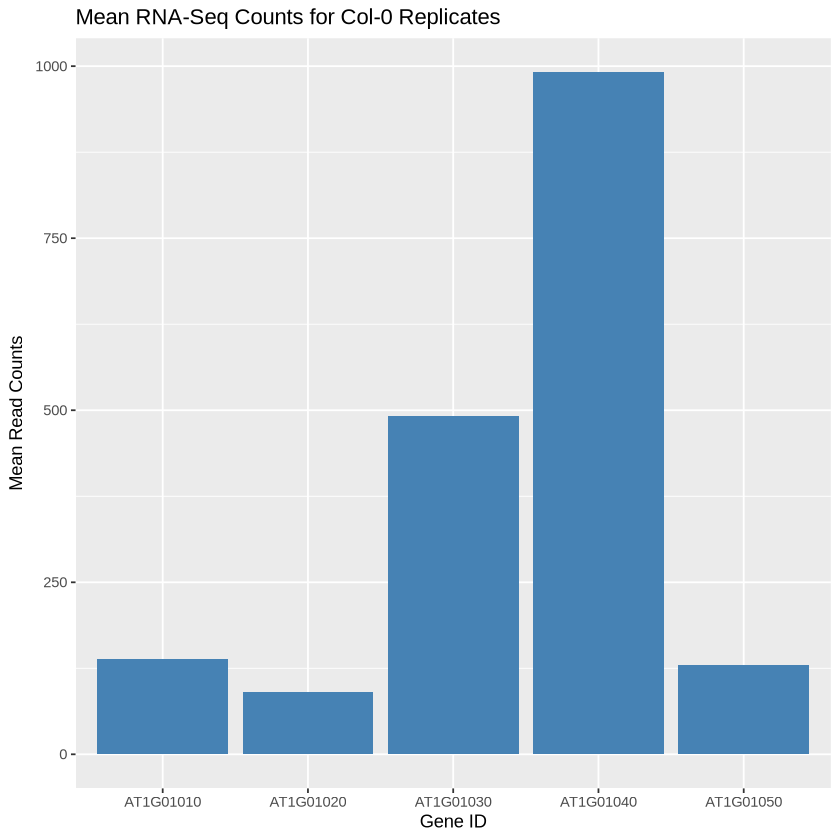

In [ ]:
library(ggplot2)

# Calculate the mean across Col-0 replicates for plotting
gene_rna_counts$mean_Col0 <- rowMeans(gene_rna_counts[, c("Col0_Rep1", "Col0_Rep2")])

# Plot mean counts
ggplot(gene_rna_counts, aes(x = gene_id, y = mean_Col0)) +
  geom_bar(stat = "identity", fill = "steelblue") +  # Bar height represents mean counts
  labs(
    title = "Mean RNA-Seq Counts for Col-0 Replicates",
    x = "Gene ID",
    y = "Mean Read Counts"
  )

Worry not, the next lab covers vizualizing graphs in `R`. We will cover the use of `ggplot2` then. 